<a href="https://colab.research.google.com/github/AtharvaDandawate/EDA/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 200
size = np.random.uniform(500, 3000, n)
noise = np.random.normal(0, 200000, n)
price = 50000 + 3000 * size + noise

X = size.reshape(-1, 1)
y = price

print("Number of houses:", len(X))
print("First 5 house sizes:", X[:5].flatten())
print("First 5 house prices:", y[:5])


Number of houses: 200
First 5 house sizes: [1436.35029712 2876.78576602 2329.98485453 1996.64621049  890.04660111]
First 5 house prices: [4223045.94703952 8726808.03750657 7098569.05824527 5897068.3478725
 3093294.70554723]


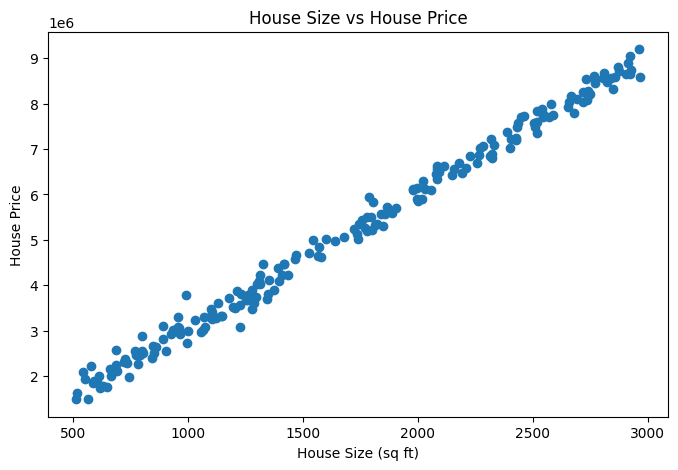

In [2]:

plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.xlabel("House Size (sq ft)")
plt.ylabel("House Price")
plt.title("House Size vs House Price")
plt.show()


In [3]:

indices = np.random.permutation(n)
split = int(0.8 * n)

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 160
Testing samples: 40


In [4]:

X_train_b = np.column_stack((
    np.ones(len(X_train)),
    X_train
))

X_test_b = np.column_stack((
    np.ones(len(X_test)),
    X_test
))

theta = np.linalg.pinv(X_train_b) @ y_train

print("Intercept:", theta[0])
print("Slope:", theta[1])


Intercept: 77549.04202804025
Slope: 2991.378146203193


In [5]:

y_pred = X_test_b @ theta

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(
        f"Actual: {actual:.2f}, "
        f"Predicted: {predicted:.2f}"
    )


Actual: 5721884.57, Predicted: 5661781.07
Actual: 6100728.48, Predicted: 5992198.71
Actual: 1888112.01, Predicted: 1849095.14
Actual: 3571056.49, Predicted: 3751179.33
Actual: 6284304.93, Predicted: 6131831.68
Actual: 5572510.90, Predicted: 5579999.82
Actual: 2975423.56, Predicted: 2968492.11
Actual: 2462309.66, Predicted: 2439758.55
Actual: 1770291.63, Predicted: 1958219.14
Actual: 3899474.81, Predicted: 3904352.37


In [6]:

theta_gd = np.zeros(X_train_b.shape[1])
learning_rate = 1e-10
epochs = 10000

for epoch in range(epochs):
    predictions = X_train_b @ theta_gd
    errors = predictions - y_train
    gradient = (2 / len(y_train)) * (X_train_b.T @ errors)
    theta_gd -= learning_rate * gradient

print("Gradient descent intercept:", theta_gd[0])
print("Gradient descent slope:", theta_gd[1])


Gradient descent intercept: 1.5089589673531445
Gradient descent slope: 3026.557799392325


In [7]:

errors = y_test - y_pred

mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)

r2 = 1 - ss_res / ss_tot

print("Mean Squared Error:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


Mean Squared Error: 38391110753.265686
RMSE: 195936.49673622748
R² Score: 0.9904550059904368


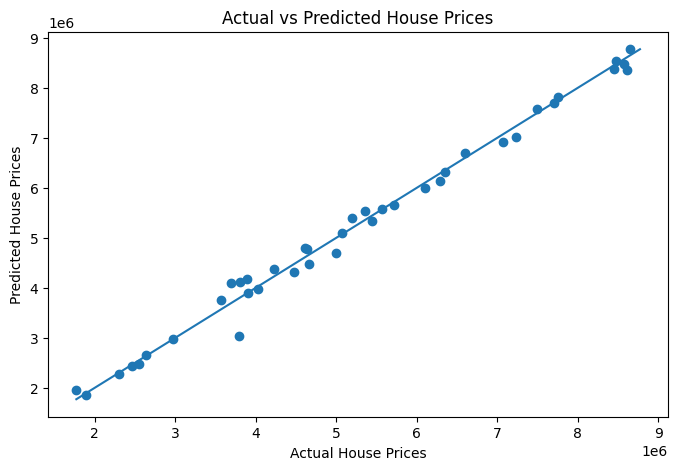

In [8]:

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper])
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()


In [9]:

y_pred_gd = X_test_b @ theta_gd

rmse_normal = np.sqrt(np.mean((y_test - y_pred) ** 2))
rmse_gd = np.sqrt(np.mean((y_test - y_pred_gd) ** 2))

print("Normal equation RMSE:", rmse_normal)
print("Gradient descent RMSE:", rmse_gd)
print("Normal equation coefficients:", theta)
print("Gradient descent coefficients:", theta_gd)


Normal equation RMSE: 195936.49673622748
Gradient descent RMSE: 197226.42447905676
Normal equation coefficients: [77549.04202804  2991.3781462 ]
Gradient descent coefficients: [1.50895897e+00 3.02655780e+03]
